# LeetCode #43: Multiply Strings

https://leetcode.com/problems/multiply-strings/

## Comparison of Approaches

| Approach | Time | Space |
| :--- | :--- | :--- |
| **Brute Force (repeated addition)** | $O(10^n \cdot m)$ | $O(m + n)$ |
| **Partial Products, Then Add** | $O(m \cdot n)$ | $O(m + n)$ |
| **Grade-School Digit Array** ★ | $O(m \cdot n)$ | $O(m+n)$ |

`m` and `n` are the number of digits in the two inputs, up to 200 each. $O(m \cdot n)$ means one small step for every pair of digits: $200 \times 200 = 40{,}000$ steps at most. $O(m + n)$ space means one array as long as the answer, at most 400 digits. $O(10^n)$ means the work grows with the *value* of a number, not its length: a 200-digit number is far beyond anything a computer could count to.

---

## Understanding the Methods

You aren't allowed to turn the strings into numbers, and a 200-digit number wouldn't fit in any built-in integer type anyway (a 64-bit integer holds about 19 digits). So the multiplication has to be done digit by digit, the way it's done on paper.

### Brute Force (repeated addition)
Add `num1` to itself `num2` times, using string addition. Correct, but if `num2` is a 200-digit number, that's more additions than there are atoms in the universe.

### Partial Products, Then Add
Exactly the paper method: multiply `num1` by each digit of `num2` to get a row, shift each row one place further left, then add all the rows up. It's the right speed, but it builds a separate string for every row and needs a separate string-addition routine.

### Optimal: Grade-School Digit Array ★
Skip the rows. Make one array of `m + n` zeros, one cell per digit of the answer. Digit `i` of `num1` times digit `j` of `num2` always lands in the same column of the answer, cell `i + j + 1`, and anything over 9 carries into the cell to its left, `i + j`. Do that for every pair, then read the array as a string, skipping leading zeros.

**Why this is better than Partial Products:** the same $m \times n$ digit multiplications, but every one of them adds straight into its final column. There are no intermediate row strings and no separate addition pass.

**Constraints:**
* $1 \leq$ num1.length, num2.length $\leq 200$
* num1 and num2 consist of digits only
* Neither num1 nor num2, except for the number `0` itself, starts with a leading zero


## Explain Like I'm a Newbie

### What the question is actually asking

Two numbers arrive as strings, possibly 200 digits long. Return their product, also as a string. You may not convert them to integers, so you have to multiply the way you learned at school.

```
      1 2 3
    x 4 5 6
    -------
      7 3 8      123 x 6
    6 1 5        123 x 5, shifted one place
  4 9 2          123 x 4, shifted two places
  ---------
  5 6 0 8 8
```

### The one idea you need: every digit pair has a fixed column

On paper you write out each row and add them at the end. But look at where things land. The `3` of 123 (position 2) times the `6` of 456 (position 2) lands in the rightmost column. Move one digit left in either number and the result moves one column left. So the column only depends on `i + j`, the sum of the two positions.

That means you don't need the rows. Keep one array of `m + n` cells, one per digit of the answer, and drop each little product straight into its column: digit `i` times digit `j` goes into cell `i + j + 1`, and whatever is over 9 carries into the cell to its left, `i + j`.

Why `m + n` cells? A 3-digit number times a 3-digit number is at most `999 x 999 = 998001`, six digits. It's never more than `m + n` digits, and sometimes it's exactly that.

### What that means in code

Loop over both strings from the right. For each pair:

1. `total = digit_i * digit_j + pos[i + j + 1]`, the new product plus what's already in that column.
2. `pos[i + j + 1] = total % 10`, keep the last digit there.
3. `pos[i + j] += total // 10`, push the carry one column left. It's `+=`, because that column may already hold something.

At the end, join the cells and strip leading zeros. If nothing is left, the answer is `"0"`.

### Mistakes people make the first time

1. **Sizing the answer as `m + n - 1` digits.** LeetCode's `123 x 456 = 56088` has exactly 5 digits, so it passes, and so does `2 x 3`. But `99 x 99 = 9801` needs 4, and the version that drops the final carry returns `"801"`.
2. **Forgetting zero.** Strip the leading zeros from `"0" x "52"` and you're left with an empty string. Neither LeetCode sample contains a zero, so only a test with one catches it.
3. **`=` instead of `+=` for the carry.** That wipes out what the column already held: `123 x 456` comes out as `45788`.
4. **Converting with `int()`.** It works in Python, which has unlimited-size integers, but it's the one thing the problem forbids.

### Things worth knowing

No cell ever gets big: the running `total` is at most 99 (81 from `9 x 9`, plus a column holding at most 18), so plain 32-bit integers are fine in every language.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Long multiplication, but without writing out the rows. Digit i of the first number times digit j of the second always lands in column i + j + 1 of an m + n digit answer, with its carry going into column i + j. So I keep one int array, add each product into its column, and strip leading zeros at the end. That's m times n tiny steps and one array the size of the answer."*

And then, unprompted: *"it's quadratic. For 200 digits that's nothing, but if you're asking about million-digit numbers, there are faster algorithms, and this isn't one."*

---

### I slide the problem across the table

I've handed you two numeric strings and asked for their product as a string, with no big-integer library and no converting to int.

> **You:** "So these can be up to 200 digits, way past 64 bits, which is why I can't just convert. Both are non-negative, no signs, no leading zeros except for zero itself. Is the output allowed to have leading zeros?"

Good question, because it decides the last line of your code. **"No: `"0"` for zero, otherwise no leading zeros."**

> **You:** "Then I need to handle a zero input explicitly, or at least make sure stripping zeros doesn't leave an empty string."

That's the clarifier earning its keep: you've already found an edge case neither sample covers.

What I don't want is *"what about negative numbers?"* The constraints say digits only.

---

### Now tell me what's actually hard about it

The multiplication itself isn't hard; everybody knows the paper method. I want to hear what makes it awkward in code:

> **You:** "On paper I'd make one row per digit of the second number, shift each row, then add them all. In code that means building n strings and writing a string adder. The fiddly part is all the shifting and aligning. What I'd really like is to know, for each pair of digits, exactly which column of the answer it affects, and add it there directly."

> **You:** "And there is a fixed column. Counting from the left, digit i times digit j contributes to column i + j + 1 of an m + n digit result, and its carry goes to column i + j. The answer can't be longer than m + n digits: 999 times 999 is 998001."

That's the insight. It came from the awkwardness, not from memory.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "One array `pos` of m + n zeros. Two nested loops from the right end of each string. Each step: multiply two digits, add what's in column i + j + 1, keep the last digit there, add the carry into column i + j. Then join, strip leading zeros, and return `"0"` if that's empty."

> **You:** "m times n steps, each constant: 40,000 at the limit. Space is the m + n array, the size of the answer, which I have to produce anyway."

I'll ask: *"can a cell overflow?"* The answer I'm after:

> **You:** "No. The column I add into has a single digit plus at most one round of carries, so at most 18. Add 81 and the total is at most 99, the carry at most 9. Ordinary ints."

---

### Now whiteboard it

```
if num1 == '0' or num2 == '0':
    return '0'
m, n = len(num1), len(num2)
pos = [0] * (m + n)
```

> **You:** "The zero check isn't strictly needed for correctness if I handle the empty string at the end, but it makes the zero case obvious and skips 40,000 multiplications by zero."

```
for i in range(m - 1, -1, -1):
    for j in range(n - 1, -1, -1):
        mul = int(num1[i]) * int(num2[j])
        p1, p2 = i + j, i + j + 1
        total = mul + pos[p2]
        pos[p2] = total % 10
        pos[p1] += total // 10
```

The line I'm watching is the last one:

> **You:** "`+=`, not `=`. Column p1 may already hold a digit from an earlier pair. Overwriting it loses that, and 123 times 456 comes out wrong."

And on the indices:

> **You:** "`p2` is where this product's units digit belongs, `p1` is one column to the left for the carry. When i and j are both 0, p1 is 0, the very first cell, which is why the array needs m + n cells rather than m + n - 1."

If you don't say that, I'll ask *"why m + n?"*

```
result = ''.join(str(d) for d in pos).lstrip('0')
return result or '0'
```

---

### Walk me through it before you say you're done

> **You:** "`99` times `99`. `pos` has 4 cells. i = 1, j = 1: 81 into cell 3, keep 1, carry 8 into cell 2. i = 1, j = 0: 81 plus the 8 already in cell 2 is 89, keep 9, carry 8 into cell 1. Then i = 0, j = 1: 81 plus cell 2's 9 is 90, keep 0, carry 9 into cell 1, now 17. Finally i = 0, j = 0: 81 plus 17 is 98, keep 8, carry 9 into cell 0. Array is 9, 8, 0, 1: 9801. All four cells used, which is the m + n case."

That trace is worth more than ten edge cases recited, because it shows a column receiving two carries and still ending up as a single digit by the time it's read.

---

### Then tell me where it breaks, before I ask

> **You:** "It's correct for any length, but it's quadratic. At 200 digits that's 40,000 steps, trivial. At a million digits it's a trillion. Real big-number libraries switch to Karatsuba, which splits each number in half and gets away with three half-size multiplications instead of four, or to FFT-based methods for really huge inputs."

> **You:** "Also, the Rust version stores the digits reversed and does the carry the other way round. Same idea, different bookkeeping, and the column formula becomes i + j instead of i + j + 1. Worth knowing so it doesn't look like a different algorithm."

That second point tells me you read all four solutions rather than one.

---

### What would worry me

- **Converting to an integer** "just to check". It's the one forbidden move.
- **Writing a string adder** for partial products when the column formula makes it unnecessary.
- **Returning an empty string for zero.** The samples won't catch it.
- **An `m + n - 1` array.** It passes both samples and loses the top digit of 99 times 99.


## Solutions

### C#

In [ ]:
public class Solution {
    public string Multiply(string num1, string num2) {
        // Anything times zero is "0"; handling it here also avoids stripping
        // every zero below and being left with an empty string
        if (num1 == "0" || num2 == "0") return "0";
        int m = num1.Length, n = num2.Length;
        // The product has at most m + n digits (999 * 999 = 998001), one cell each
        int[] pos = new int[m + n];
        // Walk both numbers from their last digit, like long multiplication on paper
        for (int i = m - 1; i >= 0; i--) {
            for (int j = n - 1; j >= 0; j--) {
                int mul = (num1[i] - '0') * (num2[j] - '0');   // '7' - '0' = 7
                // Digit i times digit j always belongs in column i + j + 1;
                // its carry goes one column left, to i + j
                int p1 = i + j, p2 = i + j + 1;
                int sum = mul + pos[p2];     // add to what this column already holds
                pos[p2] = sum % 10;          // keep the last digit here
                // += not =: column p1 may already hold a digit from another pair
                pos[p1] += sum / 10;
            }
        }
        // Copy the digits out, skipping zeros at the front
        var sb = new System.Text.StringBuilder();
        foreach (int d in pos)
            if (sb.Length > 0 || d > 0) sb.Append(d);
        return sb.Length == 0 ? "0" : sb.ToString();
    }
}

### Python

In [ ]:
class Solution:
    def multiply(self, num1: str, num2: str) -> str:
        # Anything times zero is "0"; handling it here also avoids stripping
        # every zero below and being left with an empty string
        if num1 == '0' or num2 == '0':
            return '0'
        m, n = len(num1), len(num2)
        # The product has at most m + n digits (999 * 999 = 998001), one cell each
        pos = [0] * (m + n)
        # Walk both numbers from their last digit, like long multiplication on paper
        for i in range(m - 1, -1, -1):
            for j in range(n - 1, -1, -1):
                mul = int(num1[i]) * int(num2[j])   # int() of ONE digit, not the whole string
                # Digit i times digit j always belongs in column i + j + 1;
                # its carry goes one column left, to i + j
                p1, p2 = i + j, i + j + 1
                total = mul + pos[p2]       # add to what this column already holds
                pos[p2] = total % 10        # keep the last digit here
                # += not =: column p1 may already hold a digit from another pair
                pos[p1] += total // 10
        # Join the digits and drop zeros at the front (cell 0 is often unused)
        result = ''.join(str(d) for d in pos).lstrip('0')
        return result or '0'

### Go

In [ ]:
package main

func multiply(num1 string, num2 string) string {
	// Anything times zero is "0"; handling it here also means the result
	// below can never come out empty
	if num1 == "0" || num2 == "0" {
		return "0"
	}
	m, n := len(num1), len(num2)
	// The product has at most m + n digits (999 * 999 = 998001), one cell each
	pos := make([]int, m+n)
	// Walk both numbers from their last digit, like long multiplication on paper
	for i := m - 1; i >= 0; i-- {
		for j := n - 1; j >= 0; j-- {
			mul := int(num1[i]-'0') * int(num2[j]-'0')   // byte '7' - '0' = 7
			// Digit i times digit j always belongs in column i + j + 1;
			// its carry goes one column left, to i + j
			p1, p2 := i+j, i+j+1
			sum := mul + pos[p2]   // add to what this column already holds
			pos[p2] = sum % 10     // keep the last digit here
			// += not =: column p1 may already hold a digit from another pair
			pos[p1] += sum / 10
		}
	}
	// Copy the digits out, skipping zeros at the front
	result := []byte{}
	for _, d := range pos {
		if len(result) > 0 || d > 0 {
			result = append(result, byte('0'+d))
		}
	}
	return string(result)
}

### Rust

This version reverses both digit lists first, so the ones digit is at index 0. It's the same algorithm with the columns numbered from the other end: products go into `i + j` and carries into `i + j + 1`.


In [ ]:
pub struct Solution;

impl Solution {
    pub fn multiply(num1: String, num2: String) -> String {
        // Anything times zero is "0"
        if num1 == "0" || num2 == "0" { return String::from("0"); }
        // Digits REVERSED, so index 0 is the ones digit. That flips the column
        // formula: digit i times digit j lands in cell i + j, carry in i + j + 1.
        let b1: Vec<u32> = num1.bytes().rev().map(|b| (b - b'0') as u32).collect();
        let b2: Vec<u32> = num2.bytes().rev().map(|b| (b - b'0') as u32).collect();
        let m = b1.len(); let n = b2.len();
        // The product has at most m + n digits (999 * 999 = 998001), one cell each
        let mut pos = vec![0u32; m + n];
        for i in 0..m {
            for j in 0..n {
                pos[i + j] += b1[i] * b2[j];         // add into this pair's column
                pos[i + j + 1] += pos[i + j] / 10;   // push the carry one column up
                pos[i + j] %= 10;                    // keep the last digit here
            }
        }
        // Read from the most significant end, skipping zeros at the front
        let s: String = pos.iter().rev()
            .skip_while(|&&d| d == 0)
            .map(|&d| (b'0' + d as u8) as char)
            .collect();
        if s.is_empty() { String::from("0") } else { s }
    }
}

## Example Scenarios

### 1. Common Case — LeetCode's Example
**Input:** `num1 = "123"`, `num2 = "456"`

Nine digit pairs, each added into column $i + j + 1$ of a 6-cell array. The first cell is never used, so the leading zero is stripped and the answer has 5 digits, one fewer than $m + n$. **Output:** `"56088"`

### 2. Slightly Complex — All Nines, Every Cell Used
**Input:** `num1 = "9999"`, `num2 = "9999"`

Every pair multiplies to 81, the biggest possible, so every column receives carries. Even so, no running total ever exceeds 99. The product $9999^2 = 99{,}980{,}001$ fills all $m + n = 8$ cells, which is exactly where an $m + n - 1$ sized array loses its top digit. **Output:** `"99980001"`

### 3. Edge Case: Time Factor — Two 200-Digit Numbers
**Input:** `num1` = 200 nines, `num2` = 200 nines

The longest inputs allowed: $200 \times 200 = 40{,}000$ digit multiplications into a 400-cell array, still only microseconds. The running total stays at most 99 even here, so 32-bit integers are plenty. **Output:** a 400-digit string, 199 nines, then `8`, then 199 zeros, then `1` ($= 10^{400} - 2 \cdot 10^{200} + 1$)

### 4. Edge Case: Space Factor — Times Zero
**Input:** `num1 = "0"`, `num2` = 200 nines

The guard returns `"0"` before allocating anything. Without it the code would build a 201-cell array of zeros, do 200 multiplications by zero, and strip every digit, leaving an empty string; the final `or '0'` is the second line of defence. **Output:** `"0"`

### 5. Almost-Impossible but Plausible — One Digit Makes the Answer Longer
**Input:** `num1 = "2"`, `num2` = 200 nines

Each step is $2 \times 9 = 18$ plus the carry, so a carry of 1 ripples through all 200 columns and ends in cell 0. That leading 1 is a real digit and must survive the zero-stripping. The answer is 201 digits, one longer than `num2`. **Output:** `"1"` + 199 nines + `"8"`


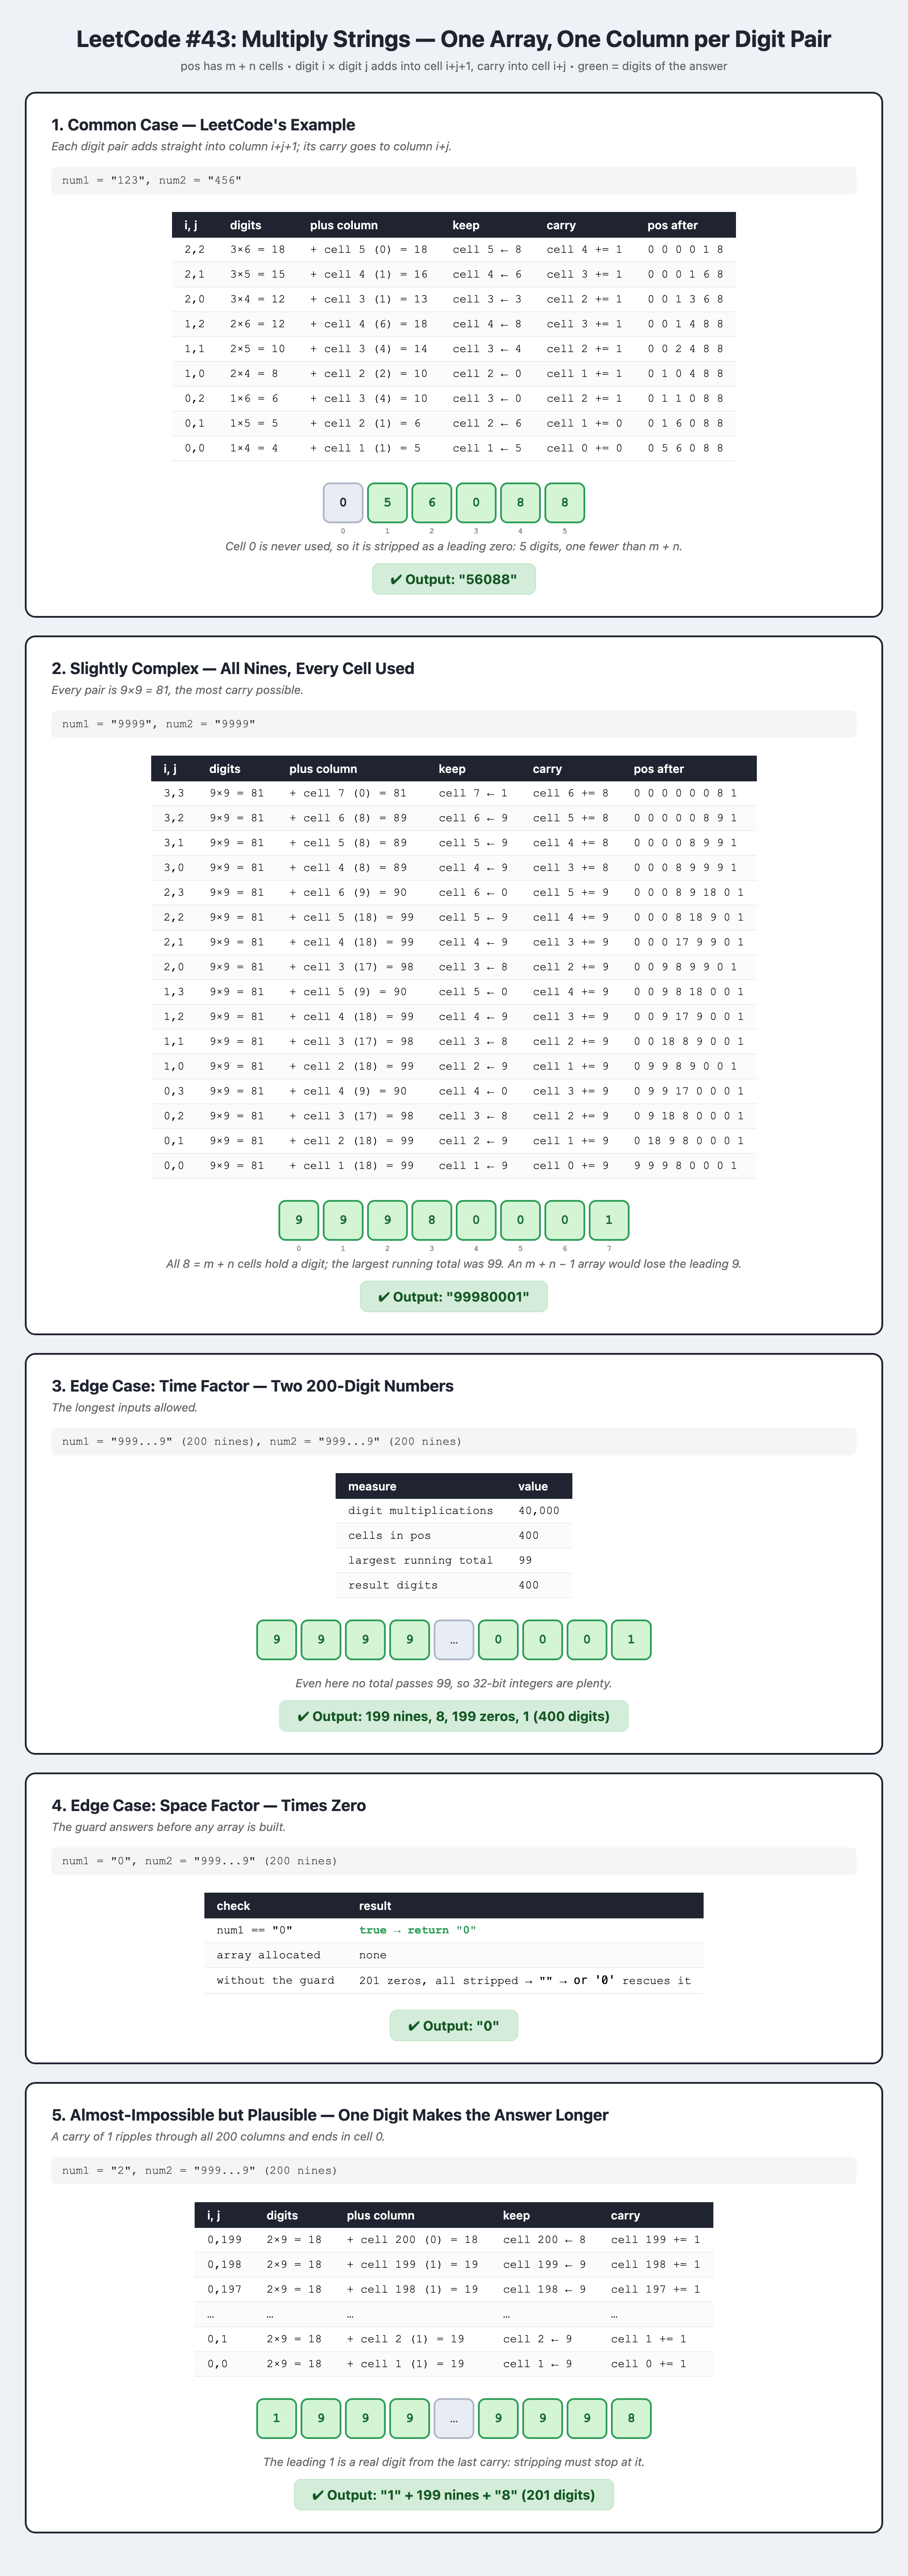

## Watch It Run

*Watch the first step: 3 × 6 goes straight into the last cell, and every later pair lands in cell i + j + 1 the same way, so no rows are ever written out.*

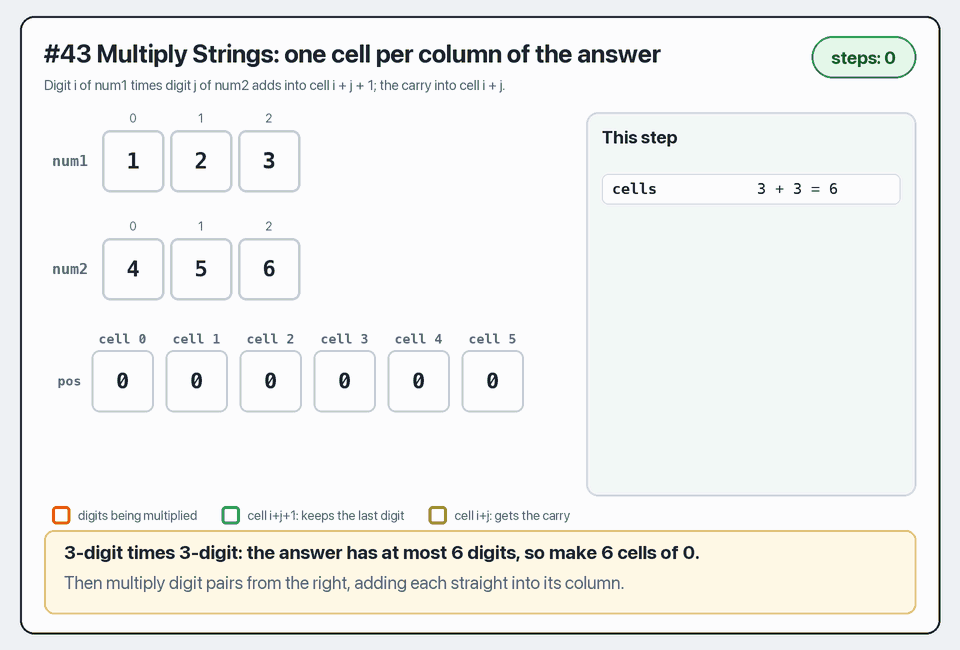

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0043.html)**